# **NASA Predictive Maintenance – Baseline Models (Member 2)**

**Task:** predict the Remaining Useful Life (RUL) of turbofan engines from 30-cycle windows of sensor readings (regression).
**Dataset:** NASA C-MAPSS turbofan degradation data, sub-set FD001 (100 training engines, 100 test engines), from the NASA Prognostics Data Repository.

This notebook contains **Member 2's work only**: the baseline models that every Neural Network will be compared against. It does **not** repeat the data preparation. It loads the already-prepared arrays that Member 1's pipeline produces (leak-free split by engine, scaler fitted on the training engines only, sliding windows of 30 cycles, 18 features).

Three baselines, as required by the project specification (section 3.3):

1. **Trivial baseline** – always predicts the mean training RUL (regression equivalent of "majority class").
2. **Ridge Regression** – the simple learned baseline (regularized linear regression).
3. **Random Forest Regressor** – an extra, stronger non-linear classical baseline.

# **Part 1 – Load the Prepared Data (output of Member 1)**

`prepared_data.npz` is exported at the end of Member 1's notebook (see the export cell in the hand-off notes). It contains:

| Array | Shape | Meaning |
|---|---|---|
| `X_train_seq`, `y_train_seq` | (14241, 30, 18), (14241,) | training windows and their RUL |
| `X_test_seq`, `y_test` | (100, 30, 18), (100,) | last window of each test engine and its true RUL |
| `val_id`, `val_cycle`, `val_rul`, `val_features` | 4070 rows | scaled rows of the 20 validation engines |
| `feature_cols`, `window_size` | – | feature names (18) and window length (30) |

In [1]:
# --- Project setup: make src/ importable and load the configuration ---
import json
import os
import sys

REPO_ROOT = os.path.abspath("..") if os.path.isdir("../src") else os.path.abspath(".")
if not os.path.isdir(os.path.join(REPO_ROOT, "src")):
    # Google Colab: clone the repository so src/ and configs/ are available.
    !git clone https://github.com/yomna-0/nasa-predictive-maintenance-rul.git
    os.chdir("nasa-predictive-maintenance-rul/notebooks")
    REPO_ROOT = os.path.abspath("..")

sys.path.insert(0, REPO_ROOT)

with open(os.path.join(REPO_ROOT, "configs", "default.json")) as f:
    CONFIG = json.load(f)

SEED = CONFIG["seed"]

In [2]:
import os
import numpy as np
import pandas as pd
from IPython.display import display

DATA_FILE = "prepared_data.npz"

if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_FILE} in the same folder as this notebook.")

In [3]:
import os
if not os.path.exists(DATA_FILE):
    for candidate in ["../prepared_data.npz", "prepared_data (1).npz"]:
        if os.path.exists(candidate):
            DATA_FILE = candidate
            break

data = np.load(DATA_FILE, allow_pickle=False)

X_train_seq = data["X_train_seq"]
y_train_seq = data["y_train_seq"]
X_test_seq  = data["X_test_seq"]
y_test      = data["y_test"]
feature_cols = data["feature_cols"].tolist()
WINDOW_SIZE  = int(data["window_size"])

val_data = pd.DataFrame({
    "id": data["val_id"],
    "cycle": data["val_cycle"],
    "RUL": data["val_rul"],
})
val_data[feature_cols] = data["val_features"]

print("Training sequences:", X_train_seq.shape, "| targets:", y_train_seq.shape)
print("Test sequences:    ", X_test_seq.shape,  "| targets:", y_test.shape)
print("Validation rows:   ", val_data.shape, "| validation engines:", val_data["id"].nunique())
print("Window size:", WINDOW_SIZE, "| Features:", len(feature_cols))
print("Feature names:", feature_cols)

Training sequences: (14241, 30, 18) | targets: (14241,)
Test sequences:     (100, 30, 18) | targets: (100,)
Validation rows:    (4070, 20) | validation engines: 20
Window size: 30 | Features: 18
Feature names: ['cycle', 'setting1', 'setting2', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [4]:
# Sanity checks on the loaded data
assert X_train_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert X_test_seq.shape[1:]  == (WINDOW_SIZE, len(feature_cols))
assert len(X_train_seq) == len(y_train_seq)
assert len(X_test_seq)  == len(y_test) == 100
assert not np.isnan(X_train_seq).any() and not np.isnan(X_test_seq).any()
assert not np.isnan(y_test).any()
print("Data checks passed.")

Data checks passed.


# **Part 2 – Baseline Models**

In [5]:
import numpy as np
import pandas as pd
from IPython.display import display

In [6]:
import time, json
import matplotlib.pyplot as plt

from src.data import create_validation_sequences
from src.models import (
    build_trivial_model,
    build_ridge,
    select_ridge_alpha,
    build_random_forest,
    flatten_windows,
)
from src.evaluate import evaluate, nasa_score

SEED = CONFIG["seed"]

Prepare Input for Baseline Models

Traditional models expect 2D input `(samples, features)`, while each sequence is 3D `(samples, 30 cycles, 18 features)`. Training uses all available sliding windows. For validation model selection, we create one reproducible simulated cutoff per validation engine: a 30-cycle window ending before failure, with the corresponding remaining RUL as its target. This better matches the censored Test setup than using the final row of fully observed training engines (whose RUL is always zero). Member 1's original validation sliding-window arrays remain available for the Neural Network members.

In [7]:
# One simulated "current time" per validation engine (function in src/data.py).
X_val_eval_seq, y_val_eval = create_validation_sequences(
    val_data, feature_cols, WINDOW_SIZE, random_state=SEED
)

print("Validation evaluation sequences:", X_val_eval_seq.shape)
print("Validation evaluation targets:", y_val_eval.shape)
print("Validation RUL range:", (float(y_val_eval.min()), float(y_val_eval.max())))

Validation evaluation sequences: (20, 30, 18)
Validation evaluation targets: (20,)
Validation RUL range: (6.0, 187.0)


In [8]:
X_train_flat = flatten_windows(X_train_seq)
X_val_flat   = flatten_windows(X_val_eval_seq)
X_test_flat  = flatten_windows(X_test_seq)

print("Training Flat Shape:  ", X_train_flat.shape)
print("Validation Flat Shape:", X_val_flat.shape)
print("Testing Flat Shape:   ", X_test_flat.shape)

Training Flat Shape:   (14241, 540)
Validation Flat Shape: (20, 540)
Testing Flat Shape:    (100, 540)


Evaluation Metrics

- **RMSE / MAE:** average error in cycles (lower is better)
- **R²:** how much of the variance the model explains (higher is better)
- **NASA Score:** the standard scoring function for this dataset. It penalizes *late* predictions (predicting more RUL than the truth) more than early ones, because a late prediction means the engine may fail before maintenance. Lower is better.

# **Baseline Model 0 – Trivial Baseline (Mean RUL)**

The simplest possible predictor: it ignores the sensors completely and always predicts the average RUL of the training set. It is the regression equivalent of "majority-class prediction". Any useful model must beat these numbers.

In [9]:
dummy = build_trivial_model()

start = time.time()
dummy.fit(X_train_flat, y_train_seq)
dummy_train_time = time.time() - start

dummy_val, dummy_val_pred   = evaluate(dummy, X_val_flat,  y_val_eval, "Trivial (Mean RUL)", "Validation")
dummy_test, dummy_test_pred = evaluate(dummy, X_test_flat, y_test,     "Trivial (Mean RUL)", "Test")

print("Constant prediction (mean training RUL):", round(float(np.ravel(dummy.constant_)[0]), 2))
print(f"Training time: {dummy_train_time:.4f} sec")
display(pd.DataFrame([dummy_val, dummy_test]).round(3))

Constant prediction (mean training RUL): 94.75
Training time: 0.0014 sec


,Model,Split,RMSE,MAE,R2,NASA Score
0,Trivial (Mean RUL),Validation,54.270,48.701,-0.099,13069.706
1,Trivial (Mean RUL),Test,45.791,36.616,-0.214,73242.892


# **Baseline Model 1 – Ridge Regression**

A linear model with L2 regularization (the simple learned baseline). It is fast and easy to interpret, and it shows how far a purely linear relationship can go.
The regularization strength `alpha` is selected using the **validation set only** (the test set is never used for tuning).

In [10]:
best_alpha, alpha_results = select_ridge_alpha(
    CONFIG["ridge_alphas"], X_train_flat, y_train_seq, X_val_flat, y_val_eval
)

for a, rmse in alpha_results:
    print(f"alpha = {a:<7} -> Validation RMSE = {rmse:.3f}")

print("\nBest alpha:", best_alpha)

alpha = 0.1     -> Validation RMSE = 26.562
alpha = 1       -> Validation RMSE = 26.561
alpha = 10      -> Validation RMSE = 26.548
alpha = 100     -> Validation RMSE = 26.462
alpha = 1000    -> Validation RMSE = 26.451

Best alpha: 1000


In [11]:
ridge = build_ridge(best_alpha)

start = time.time()
ridge.fit(X_train_flat, y_train_seq)
ridge_train_time = time.time() - start

ridge_val, ridge_val_pred   = evaluate(ridge, X_val_flat,  y_val_eval, "Ridge Regression", "Validation")
ridge_test, ridge_test_pred = evaluate(ridge, X_test_flat, y_test,    "Ridge Regression", "Test")

print(f"Training time: {ridge_train_time:.2f} sec")
display(pd.DataFrame([ridge_val, ridge_test]).round(3))

Training time: 0.15 sec


,Model,Split,RMSE,MAE,R2,NASA Score
0,Ridge Regression,Validation,26.451,23.279,0.739,422.771
1,Ridge Regression,Test,26.108,22.420,0.605,3199.729


# **Baseline Model 2 – Random Forest Regressor**

An ensemble of decision trees. It can capture non-linear relationships between the sensors and the RUL without needing any scaling or manual feature engineering.

In [12]:
rf = build_random_forest(SEED, **CONFIG["random_forest"])

start = time.time()
rf.fit(X_train_flat, y_train_seq)
rf_train_time = time.time() - start

rf_val, rf_val_pred   = evaluate(rf, X_val_flat,  y_val_eval, "Random Forest", "Validation")
rf_test, rf_test_pred = evaluate(rf, X_test_flat, y_test,    "Random Forest", "Test")

print(f"Training time: {rf_train_time:.2f} sec")
display(pd.DataFrame([rf_val, rf_test]).round(3))

Training time: 20.89 sec


,Model,Split,RMSE,MAE,R2,NASA Score
0,Random Forest,Validation,25.806,20.596,0.752,431.335
1,Random Forest,Test,25.304,18.939,0.629,4533.579


# **Comparison Between the Baseline Models**

In [13]:
results_df = pd.DataFrame([
    dummy_val, dummy_test,
    ridge_val, ridge_test,
    rf_val, rf_test
])
results_df["Train Time (s)"] = (
    [dummy_train_time] * 2 + [ridge_train_time] * 2 + [rf_train_time] * 2
)

display(results_df.round(3))

val_only = (
    results_df[results_df["Split"] == "Validation"]
    .set_index("Model")
)
test_only = (
    results_df[results_df["Split"] == "Test"]
    .set_index("Model")
)

# Select the baseline using Validation RMSE only.
# Test results are reserved for final reporting and are never used for selection.
best_model = val_only["RMSE"].idxmin()

print("Best baseline selected using Validation RMSE:", best_model)
print("\nValidation metrics:")
display(val_only[["RMSE", "MAE", "R2", "NASA Score"]].round(4))

print("\nFinal Test metrics (reporting only; not used for model selection):")
display(test_only[["RMSE", "MAE", "R2", "NASA Score"]].round(4))

,Model,Split,RMSE,MAE,R2,NASA Score,Train Time (s)
0,Trivial (Mean RUL),Validation,54.270,48.701,-0.099,13069.706,0.001
1,Trivial (Mean RUL),Test,45.791,36.616,-0.214,73242.892,0.001
2,Ridge Regression,Validation,26.451,23.279,0.739,422.771,0.150
3,Ridge Regression,Test,26.108,22.420,0.605,3199.729,0.150
4,Random Forest,Validation,25.806,20.596,0.752,431.335,20.892
5,Random Forest,Test,25.304,18.939,0.629,4533.579,20.892


Best baseline selected using Validation RMSE: Random Forest

Validation metrics:


,RMSE,MAE,R2,NASA Score
Model,,,,
Trivial (Mean RUL),54.2698,48.7012,-0.0985,13069.7061
Ridge Regression,26.4512,23.2794,0.7390,422.7708
Random Forest,25.8065,20.5956,0.7516,431.3350



Final Test metrics (reporting only; not used for model selection):


,RMSE,MAE,R2,NASA Score
Model,,,,
Trivial (Mean RUL),45.7905,36.6155,-0.2142,73242.8922
Ridge Regression,26.1083,22.4197,0.6053,3199.7286
Random Forest,25.3043,18.9393,0.6292,4533.5788


Improvement over the Trivial Baseline

How much better is each learned baseline than simply predicting the mean RUL? This is the number every Neural Network must also beat.

In [14]:
trivial_name = "Trivial (Mean RUL)"
improvement = pd.DataFrame({
    "Test RMSE": test_only["RMSE"],
    "Test MAE": test_only["MAE"],
    "RMSE improvement vs Trivial (%)":
        (1 - test_only["RMSE"] / test_only.loc[trivial_name, "RMSE"]) * 100,
    "MAE improvement vs Trivial (%)":
        (1 - test_only["MAE"] / test_only.loc[trivial_name, "MAE"]) * 100,
})
display(improvement.round(2))

,Test RMSE,Test MAE,RMSE improvement vs Trivial (%),MAE improvement vs Trivial (%)
Model,,,,
Trivial (Mean RUL),45.79,36.62,0.00,0.00
Ridge Regression,26.11,22.42,42.98,38.77
Random Forest,25.30,18.94,44.74,48.28


Visualizations

The plots show the actual vs predicted RUL for the 100 test engines (points close to the red line are good predictions) and the metric comparison between the models.

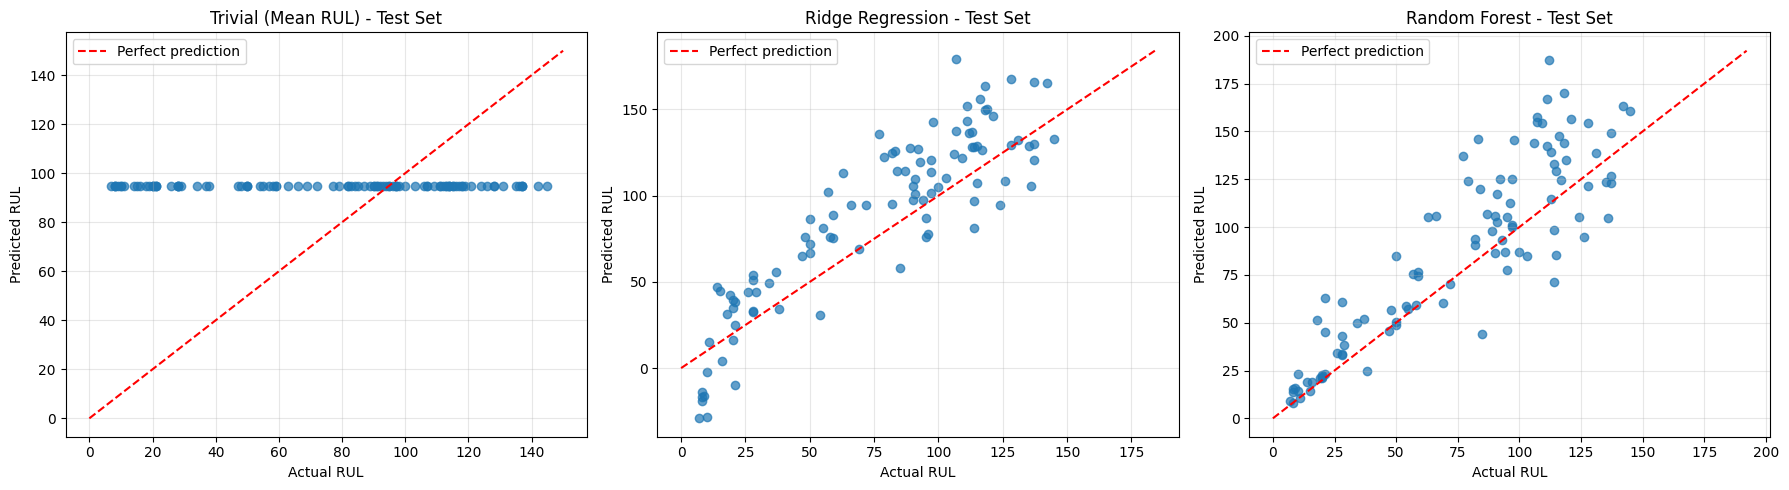

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, pred, title in zip(
    axes,
    [dummy_test_pred, ridge_test_pred, rf_test_pred],
    ["Trivial (Mean RUL)", "Ridge Regression", "Random Forest"]
):
    ax.scatter(y_test, pred, alpha=0.7)
    lims = [0, max(y_test.max(), pred.max()) + 5]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_xlabel("Actual RUL")
    ax.set_ylabel("Predicted RUL")
    ax.set_title(f"{title} - Test Set")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

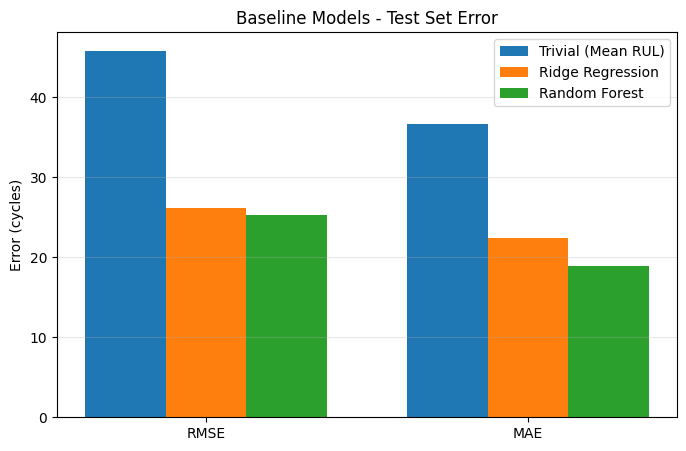

In [16]:
metrics = ["RMSE", "MAE"]
names = ["Trivial (Mean RUL)", "Ridge Regression", "Random Forest"]
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
for i, nm in enumerate(names):
    ax.bar(x + (i - 1) * width, [test_only.loc[nm, m] for m in metrics], width, label=nm)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Error (cycles)")
ax.set_title("Baseline Models - Test Set Error")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.show()

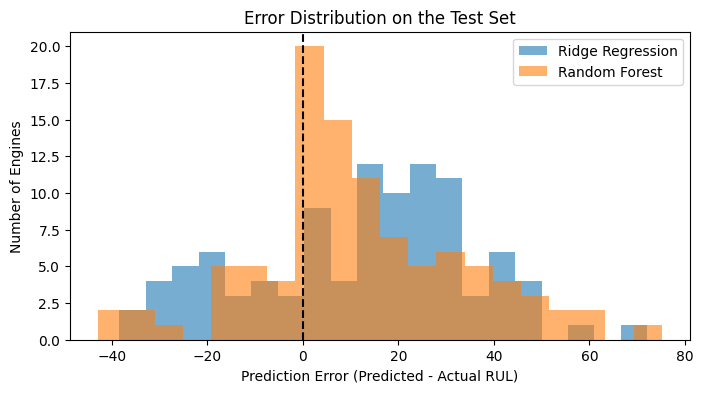

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))

for pred, name in [(ridge_test_pred, "Ridge Regression"), (rf_test_pred, "Random Forest")]:
    ax.hist(pred - y_test, bins=20, alpha=0.6, label=name)

ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Prediction Error (Predicted - Actual RUL)")
ax.set_ylabel("Number of Engines")
ax.set_title("Error Distribution on the Test Set")
ax.legend()
plt.show()

# **Save Baseline Results (for comparison with the Neural Networks)**

The results are saved to files so the rest of the team can load them and put them in the same table as the Neural Network results.

In [18]:
results_df.round(4).to_csv("baseline_results.csv", index=False)

np.save("baseline_trivial_test_pred.npy", dummy_test_pred)
np.save("baseline_ridge_test_pred.npy", ridge_test_pred)
np.save("baseline_rf_test_pred.npy", rf_test_pred)

with open("baseline_results.json", "w") as f:
    json.dump(results_df.round(4).to_dict(orient="records"), f, indent=2)

print("Saved: baseline_results.csv, baseline_results.json, "
      "baseline_trivial_test_pred.npy, baseline_ridge_test_pred.npy, baseline_rf_test_pred.npy")

# On Google Colab, uncomment to download the files:
# files.download("baseline_results.csv")
# files.download("baseline_results.json")

Saved: baseline_results.csv, baseline_results.json, baseline_trivial_test_pred.npy, baseline_ridge_test_pred.npy, baseline_rf_test_pred.npy


# **Summary of Baseline Results**

- Three baselines are reported: a **trivial** mean-RUL predictor, **Ridge Regression** (simple learned baseline) and **Random Forest** (stronger classical baseline).
- The selected baseline is determined by the **lowest Validation RMSE**.
- Validation uses one reproducible simulated pre-failure cutoff per held-out engine, so its target has positive remaining life, similar to the censored Test setup.
- The **Test set is used only for final evaluation** after model selection; it is not used for tuning or choosing the model.
- Compare RMSE, MAE, R², and NASA Score for all models on Validation and Test.
- For a fair final comparison, Neural Network members should use the same validation cutoff protocol when reporting model-selection metrics, and must beat the Trivial baseline first.

In [19]:
print(f"Selected baseline (Validation RMSE): {best_model}")
print("\nSelected model - Validation results:")
display(val_only.loc[[best_model], ["RMSE", "MAE", "R2", "NASA Score"]].round(4))

print("\nSelected model - final Test results:")
display(test_only.loc[[best_model], ["RMSE", "MAE", "R2", "NASA Score"]].round(4))

print("\nReminder: Test results are for final reporting only, not model selection.")

Selected baseline (Validation RMSE): Random Forest

Selected model - Validation results:


,RMSE,MAE,R2,NASA Score
Model,,,,
Random Forest,25.8065,20.5956,0.7516,431.335



Selected model - final Test results:


,RMSE,MAE,R2,NASA Score
Model,,,,
Random Forest,25.3043,18.9393,0.6292,4533.5788



Reminder: Test results are for final reporting only, not model selection.
